# Notebook 3 — Flower classification with pretrained ResNet
# ノートブック3：学習済みResNetを使った花画像分類

**Framework / フレームワーク:** PyTorch + Torchvision  
**Suggested lesson / 授業の目安:** 45–75 minutes after the basic Flowers CNN notebook; pretrained weights and data must be downloaded first. / 基礎編の花分類ノートブックの後に45〜75分程度。重みとデータは事前のダウンロードを推奨します。

### What will you learn? / 学習目標
1. **Transfer learning:** reuse visual features learned from a large dataset. / **転移学習：** 大規模データで学んだ画像特徴を再利用します。
2. **Feature extraction:** freeze the pretrained backbone and train only a new classifier. / **特徴抽出：** 学習済みの本体を固定して、分類層のみ学習します。
3. **Fine-tuning:** unfreeze the last residual block and adjust it with a smaller learning rate. / **ファインチューニング：** 最後の残差ブロックを学習可能にし、小さな学習率で調整します。
4. **Interpret results:** plots, confusion matrix, errors, and intermediate feature maps. / **結果の解釈：** 学習曲線、混同行列、誤分類例、中間特徴マップを確認します。

### Which model? / モデルの選択

| Model / モデル | Why choose it? / 選ぶ理由 | Replacement classifier / 交換する最終層 |
|---|---|---|
| **ResNet18 (default / 推奨)** | Faster; suitable for one lesson and CPU/Mac. / 高速で授業向き | `Linear(512, 5)` |
| **ResNet50 (optional / 発展)** | Larger model, heavier computation and memory; not guaranteed to improve flower results. / 高容量だが重く、精度向上は保証されない | `Linear(2048, 5)` |

**Five labels / 5クラス:** `daisy`, `dandelion`, `roses`, `sunflowers`, `tulips`.

**Important / 重要:** The notebook contains no fabricated accuracy results. Actual plots and numbers appear only after **you train the model**. / 精度を事前に作りません。実行後の結果を表示します。

## 0. Environment and reproducibility / 実行環境と再現性

**EN:** Use your existing `cnn-teaching` conda environment (Python 3.11) and the **same packages** as the two previous notebooks. The pretrained weights download on the first run. CUDA (NVIDIA), MPS (Apple Silicon), or CPU will be selected automatically. A CPU-only quick mode uses a smaller **training and validation subset**; the final test set remains untouched.

**日本語：** 既存の `cnn-teaching` Anaconda環境（Python 3.11）を使えます。追加の機械学習ライブラリは不要です。学習済みの重みは初回実行時に取得します。CUDA・MPS・CPUを自動選択します。CPU向け短縮モードでは**学習・検証データだけ**一部を使い、テストデータは全件を保持します。

```bash
conda activate cnn-teaching
python -m pip install -r requirements.txt
python -m pip check
jupyter lab
```

**Troubleshooting / 注意:** If model weights fail to download because of a network restriction, connect to the Internet once, run this notebook, then the weights are cached in `~/.cache/torch/hub/checkpoints` (or your configured torch hub directory). / ネットワーク制限で重みを取得できない場合、最初の一度だけ接続してダウンロードしてください。

In [2]:
# Imports / ライブラリの読み込み
from pathlib import Path
import copy
import json
import random
import tarfile
import time
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms
plt.rcParams["font.family"] = "Hiragino Sans"
plt.rcParams["axes.unicode_minus"] = False

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
else:
    DEVICE = torch.device('cpu')

# ResNet18 is practical for a short class; change to 'resnet50' for comparison.
# 授業ではResNet18が推奨。'resnet50' にすると比較できます。
MODEL_NAME = 'resnet18'  # 'resnet18' or 'resnet50'
assert MODEL_NAME in ('resnet18', 'resnet50')

QUICK_DEMO = (DEVICE.type == 'cpu')  # Set False to use all images / 全画像を使うならFalse
BATCH_SIZE = 16 if DEVICE.type == 'cpu' or MODEL_NAME == 'resnet50' else 32
HEAD_EPOCHS = 2 if QUICK_DEMO else 3
FINETUNE_EPOCHS = 1 if QUICK_DEMO else 3
NUM_WORKERS = 0  # Reliable in local Windows/macOS notebooks / ローカル環境で安定

print('PyTorch:', torch.__version__)
print('Torchvision:', __import__('torchvision').__version__)
print('Device / デバイス:', DEVICE)
print('Model / モデル:', MODEL_NAME)
print('Quick demo / 短縮モード:', QUICK_DEMO)
print('Batch size / バッチサイズ:', BATCH_SIZE)

PyTorch: 2.5.1
Torchvision: 0.20.1
Device / デバイス: mps
Model / モデル: resnet18
Quick demo / 短縮モード: False
Batch size / バッチサイズ: 32


## 1. Download or reuse the flower dataset / 花データの再利用・ダウンロード

**EN:** This is **the same TensorFlow `flower_photos` dataset** used in Notebook 2, although our models are trained in PyTorch. We look for it under `./flower_data/flower_photos`. When you run the notebooks in different folders, update `DATA_ROOT` below to point to the same dataset so you do not download it twice. The archive is checked before extraction to reject unsafe paths and links.

**日本語：** 2冊目のノートブックと同じ `flower_photos` を使用します。学習はPyTorchで行います。画像が `./flower_data/flower_photos` にある場合、再ダウンロードしません。別フォルダから実行する場合は `DATA_ROOT` を既存データの場所に変更してください。解凍時には不正なパスやリンクを確認します。

Source / 配布元: https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz

In [3]:
DATA_ROOT = Path('./flower_data')  # Change if Notebook 2 stored data elsewhere
FLOWER_DIR = DATA_ROOT / 'flower_photos'
ARCHIVE = DATA_ROOT / 'flower_photos.tgz'
URL = 'https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz'
DATA_ROOT.mkdir(parents=True, exist_ok=True)

if not FLOWER_DIR.is_dir():
    if not ARCHIVE.is_file():
        print('Downloading flower dataset / 花画像をダウンロード中...')
        urllib.request.urlretrieve(URL, ARCHIVE)
    # Validate *all* members before extracting any files.
    with tarfile.open(ARCHIVE, 'r:gz') as archive:
        entries = archive.getmembers()
        for member in entries:
            parts = Path(member.name).parts
            if (member.name.startswith('/') or '..' in parts
                    or not (member.isfile() or member.isdir())):
                raise ValueError('Unsafe archive entry: ' + member.name)
        for member in entries:
            target = DATA_ROOT / member.name
            if member.isdir():
                target.mkdir(parents=True, exist_ok=True)
            else:
                target.parent.mkdir(parents=True, exist_ok=True)
                with archive.extractfile(member) as src, target.open('wb') as dst:
                    import shutil
                    shutil.copyfileobj(src, dst)

base = datasets.ImageFolder(FLOWER_DIR)
class_names = base.classes
num_classes = len(class_names)
assert num_classes == 5, f'Expected five classes, got {class_names}'
print('Dataset directory / データ保存先:', FLOWER_DIR.resolve())
print('Classes / クラス:', class_names)
print('Total images / 画像数:', len(base))

Dataset directory / データ保存先: /Users/matustanonwong/Desktop/Assistant Professor /Fall Semester 2026/研修１/codes/Week-2/flower_data/flower_photos
Classes / クラス: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Total images / 画像数: 3670


## 2. Split the data identically to Notebook 2 / 2冊目と同じデータ分割

**EN:** For a valid comparison with your CNN trained from scratch, use the **same seed and two-stage stratified split**: 70% training, 15% validation, 15% test. Stratification approximately preserves the fraction of each flower class. Only training data updates weights, only validation data chooses the best model, and the test set is evaluated **once after selecting the final model**.

**日本語：** 2冊目の自作CNNと公平に比較するため、**同じ乱数シードと層化分割**（学習70％、検証15％、テスト15％）を使用します。各集合でクラス割合が大きく変わらないようにします。テストデータは最終モデルを決めた**後に一度だけ**評価します。

**Leakage caution / データリークへの注意:** Images do not overlap between splits, but similar/duplicate photographs from the source might still exist. / 同一画像の重複は避けていますが、元データに類似写真が存在する可能性はあります。

Full split sizes / 全データ分割: {'train': 2569, 'val': 550, 'test': 551}
Used in this run / 今回使用: {'train': 2569, 'val': 550, 'test': 551}


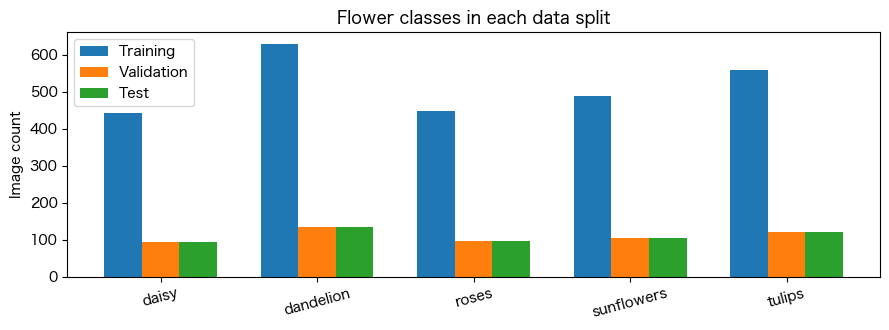

In [4]:
all_indices = np.arange(len(base))
all_labels = np.asarray(base.targets)
train_idx, remaining_idx = train_test_split(
    all_indices, test_size=0.30, stratify=all_labels, random_state=SEED
)
val_idx, test_idx = train_test_split(
    remaining_idx, test_size=0.50,
    stratify=all_labels[remaining_idx], random_state=SEED
)
assert not (set(train_idx) & set(val_idx))
assert not (set(train_idx) & set(test_idx))
assert not (set(val_idx) & set(test_idx))

print('Full split sizes / 全データ分割:',
      {'train': len(train_idx), 'val': len(val_idx), 'test': len(test_idx)})

# For CPU demonstrations, sample each class within the *existing* train/val splits.
# CPU授業用：既存分割の中から各クラス一定枚数を抽出（テストは変更しない）
def cap_per_class(indices, labels, per_class, seed):
    rng = np.random.default_rng(seed)
    parts = []
    for cls in range(len(class_names)):
        group = np.asarray(indices)[labels[np.asarray(indices)] == cls]
        parts.append(rng.choice(group, size=min(len(group), per_class), replace=False))
    return np.sort(np.concatenate(parts)).astype(int)

if QUICK_DEMO:
    train_use = cap_per_class(train_idx, all_labels, per_class=75, seed=SEED)
    val_use = cap_per_class(val_idx, all_labels, per_class=20, seed=SEED + 1)
else:
    train_use, val_use = train_idx, val_idx

print('Used in this run / 今回使用:',
      {'train': len(train_use), 'val': len(val_use), 'test': len(test_idx)})

fig, ax = plt.subplots(figsize=(9, 3.4))
x = np.arange(num_classes)
for dx, subset, label in [(-0.24, train_use, 'Training'),
                           (0, val_use, 'Validation'),
                           (0.24, test_idx, 'Test')]:
    values = np.bincount(all_labels[subset], minlength=num_classes)
    ax.bar(x + dx, values, width=0.24, label=label)
ax.set_xticks(x, class_names, rotation=15)
ax.set_ylabel('Image count')
ax.set_title('Flower classes in each data split')
ax.legend()
plt.tight_layout()
plt.show()

## 3. Preprocessing for a pretrained network / 学習済みモデル用の前処理

**EN:** In Notebook 2, images were resized to **96×96** and normalized around 0.5. Pretrained ResNet weights expect a **different preprocessing pipeline**. We use **224×224** crops and the ImageNet channel statistics bundled with the selected pretrained weights. For evaluation, `weights.transforms()` supplies the correct resize, crop, and normalization automatically. For training, we add *only training-time* random cropping/flipping and the same normalization.

**日本語：** 2冊目では **96×96** に変換し、0.5を中心に正規化しました。しかしImageNetで学習済みのResNetには**それに合った前処理**が必要です。ここでは **224×224** の画像とImageNetのチャネル平均・標準偏差を使います。検証・テストでは `weights.transforms()` を利用し、適切なサイズ変更・切り出し・正規化を自動適用します。学習時のみランダムな切り出し・左右反転を加えます。

**Crucial / 重要:** Incorrect normalization often lowers pretrained model performance. / 正規化を間違えると学習済みモデルの性能が下がる可能性があります。

Batch tensor shape / バッチの形: (32, 3, 224, 224)
Training mean / 平均: (0.485, 0.456, 0.406)
Training std / 標準偏差: (0.229, 0.224, 0.225)


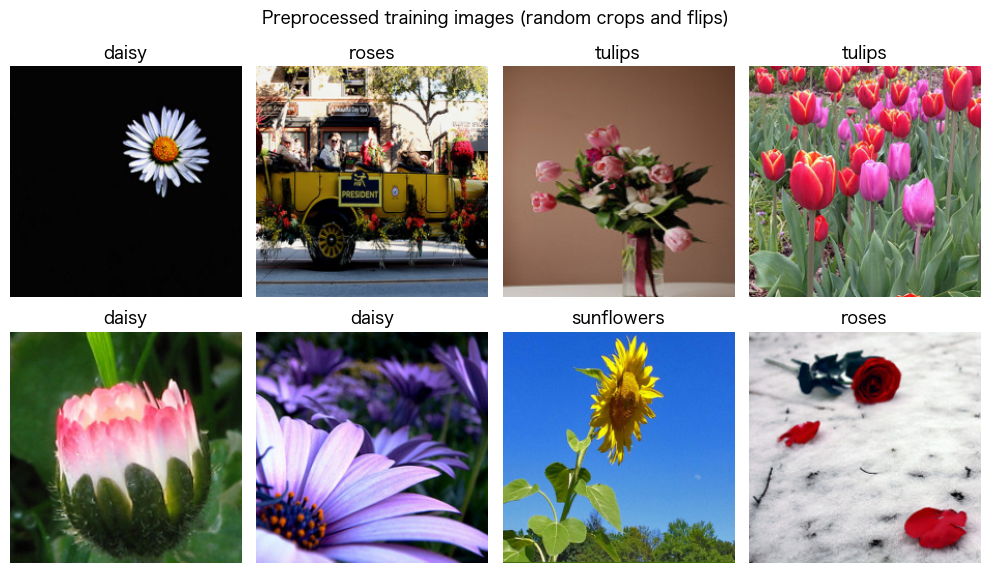

In [6]:
# Choose official weights first: these also define the preprocessing.
# 重みの種類を決めると推奨の前処理も決まります。
if MODEL_NAME == 'resnet18':
    weights = models.ResNet18_Weights.DEFAULT
else:
    weights = models.ResNet50_Weights.DEFAULT

preprocess = weights.transforms()
mean = tuple(preprocess.mean)
std = tuple(preprocess.std)

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.75, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])
eval_transform = preprocess  # Official Torchvision inference transforms / 公式の前処理

train_full = datasets.ImageFolder(FLOWER_DIR, transform=train_transform)
eval_full = datasets.ImageFolder(FLOWER_DIR, transform=eval_transform)
train_data = Subset(train_full, list(map(int, train_use)))
val_data = Subset(eval_full, list(map(int, val_use)))
test_data = Subset(eval_full, list(map(int, test_idx)))

train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS)

def denormalize(x):
    """Convert a CHW normalized Tensor to an HWC RGB image in [0,1]."""
    mean_t = torch.tensor(mean).view(3, 1, 1)
    std_t = torch.tensor(std).view(3, 1, 1)
    rgb = x.detach().cpu() * std_t + mean_t
    return rgb.clamp(0, 1).permute(1, 2, 0).numpy()

example_batch, example_targets = next(iter(train_loader))
print('Batch tensor shape / バッチの形:', tuple(example_batch.shape))
print('Training mean / 平均:', mean)
print('Training std / 標準偏差:', std)
fig, axes = plt.subplots(2, 4, figsize=(10, 6))
for ax, rgb, target in zip(axes.flat, example_batch[:8], example_targets[:8]):
    ax.imshow(denormalize(rgb))
    ax.set_title(class_names[int(target)])
    ax.axis('off')
plt.suptitle('Preprocessed training images (random crops and flips)')
plt.tight_layout()
plt.show()

## 4. What does transfer learning mean? / 転移学習とは？

**EN:** ResNet was originally trained to classify **1,000 ImageNet categories**. Earlier convolutional layers already respond to useful image patterns (edges, textures, object parts). Flower classification needs only **five** outputs. We keep the pretrained body (the *backbone*) and replace the last fully connected classification layer (`fc`). We do **not** retrain 1,000 flower classes.

**日本語：** ResNetはもともとImageNetの**1,000種類**を分類するために学習されています。前半の畳み込み層にはエッジや模様、物体の一部などを表現する重みが含まれています。花分類では**5種類**だけを出力すればよいので、学習済みの本体（バックボーン）を残し、最後の全結合層 `fc` を置き換えます。

### Two training phases / 2段階の学習

1. **Feature extraction / 特徴抽出:** Freeze *all* backbone parameters; train only the new `fc`. / バックボーン全体を固定し、`fc` だけ更新。
2. **Fine-tuning / ファインチューニング:** Unfreeze `layer4` and `fc`; use a **smaller LR for layer4**. / 最後の `layer4` と `fc` を更新。`layer4` は小さな学習率。

**Why freeze BatchNorm? / BatchNormを固定する理由：** When a frozen backbone is put into training mode, BatchNorm can still change its *running statistics*. We set BatchNorm layers whose parameters are frozen to evaluation mode during training, preventing that hidden change. / 凍結済み層でもBatchNormの内部統計が変わり得ます。凍結済みBatchNormは評価モードにして統計更新を防ぎます。

In [7]:
# Download official ImageNet weights on first use / 初回は重みをダウンロード
if MODEL_NAME == 'resnet18':
    model = models.resnet18(weights=weights)
else:
    model = models.resnet50(weights=weights)

original_input_features = model.fc.in_features
model.fc = nn.Linear(original_input_features, num_classes)
model = model.to(DEVICE)

def count_parameters(module):
    total = sum(p.numel() for p in module.parameters())
    trainable = sum(p.numel() for p in module.parameters() if p.requires_grad)
    return total, trainable

print('Original ResNet fc input features / 最終層への特徴数:', original_input_features)
print('New flower classifier / 新しい分類層:', model.fc)
print('Output classes / 出力クラス数:', model.fc.out_features)
print('Total, trainable parameters / 全体・学習可能:', count_parameters(model))

# Verify the model's output: B images x 5 flower logits.
# 出力は画像の枚数 x 5クラス分のスコアです。
model.eval()
with torch.no_grad():
    test_logits = model(example_batch[:2].to(DEVICE))
print('Sample logits shape / 出力形状:', tuple(test_logits.shape))
assert test_logits.shape == (2, num_classes)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/matustanonwong/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100.0%


Original ResNet fc input features / 最終層への特徴数: 512
New flower classifier / 新しい分類層: Linear(in_features=512, out_features=5, bias=True)
Output classes / 出力クラス数: 5
Total, trainable parameters / 全体・学習可能: (11179077, 11179077)
Sample logits shape / 出力形状: (2, 5)


### Why is this architecture different from our small CNN? / 自作CNNとの違い

**EN:** ResNet includes skip connections (*residual connections*) that allow a block to add its input to a learned transformation. This helps training deep networks. ResNet has an **adaptive average pooling layer inside the model**, followed by `fc`.

**日本語：** ResNetには、あるブロックの入力を変換結果に足す**残差接続（スキップ接続）**があります。深いネットワークの学習を助けます。ResNet本体には**適応的平均プーリング**が含まれ、その後に `fc` が続きます。

For a 224×224 input / 224×224入力の場合：

| Stage / 段階 | ResNet18 output / 出力 | ResNet50 output / 出力 |
|---|---|---|
| Input / 入力 | 3×224×224 | 3×224×224 |
| Stem: conv1 + maxpool | 64×56×56 | 64×56×56 |
| layer1 | 64×56×56 | 256×56×56 |
| layer2 | 128×28×28 | 512×28×28 |
| layer3 | 256×14×14 | 1024×14×14 |
| layer4 | 512×7×7 | 2048×7×7 |
| Adaptive avgpool / 適応的平均 | 512×1×1 | 2048×1×1 |
| Flatten + new fc / 最終分類 | **5 logits** | **5 logits** |

**Note / 注:** The exact shape descriptions assume standard 224×224 preprocessing. / この表は224×224入力のときの形状です。

In [8]:
# Hook-based shape inspection; works for ResNet18 and ResNet50.
# hookによって主要な層の出力サイズを記録します。
shape_cache = {}
handles = []
for name in ['conv1', 'maxpool', 'layer1', 'layer2', 'layer3', 'layer4', 'avgpool', 'fc']:
    layer = getattr(model, name)
    def record_shape(module, inputs, output, key=name):
        shape_cache[key] = tuple(output.shape)
    handles.append(layer.register_forward_hook(record_shape))

try:
    model.eval()
    with torch.no_grad():
        _ = model(example_batch[:1].to(DEVICE))
finally:
    for handle in handles:
        handle.remove()

print('Layer outputs (batch dimension included) / バッチ次元を含む形状:')
for key, size in shape_cache.items():
    print(f'{key:10s}: {size}')

Layer outputs (batch dimension included) / バッチ次元を含む形状:
conv1     : (1, 64, 112, 112)
maxpool   : (1, 64, 56, 56)
layer1    : (1, 64, 56, 56)
layer2    : (1, 128, 28, 28)
layer3    : (1, 256, 14, 14)
layer4    : (1, 512, 7, 7)
avgpool   : (1, 512, 1, 1)
fc        : (1, 5)


## 5. Phase A — train only the new classifier / 第1段階：分類層だけ学習

**EN:** The pretrained layers are fixed; only the last `Linear(...,5)` learns flower-specific class boundaries. This is usually faster and requires fewer trainable parameters. The five outputs are raw **logits**; cross-entropy loss calculates the necessary softmax internally.

**日本語：** 学習済みの層を固定し、最後の `Linear(...,5)` だけで花の分類境界を学習します。更新するパラメータ数が少なく、一般に計算を抑えられます。5つの出力は**logit**であり、交差エントロピー損失の前に別途softmaxを適用しません。

In [9]:
# Freeze all pretrained parameters / すべての学習済みパラメータを凍結
for param in model.parameters():
    param.requires_grad = False

# Train only the replacement classifier / 新しい分類層だけを更新
for param in model.fc.parameters():
    param.requires_grad = True

print('Total / trainable:', count_parameters(model))
print('Trainable names / 学習するパラメータ名:')
for name, param in model.named_parameters():
    if param.requires_grad:
        print(' ', name, tuple(param.shape))

Total / trainable: (11179077, 2565)
Trainable names / 学習するパラメータ名:
  fc.weight (5, 512)
  fc.bias (5,)


### The training loop, explained / 学習ループの説明

**EN:** For each batch: (1) run a forward pass; (2) compute cross-entropy loss; (3) compute gradients with `loss.backward()`; (4) update **only trainable** parameters using the optimizer. Validation uses `torch.no_grad()` and never updates the model. For each phase, we keep weights from the epoch with the **lowest validation loss**.

**日本語：** 各バッチで (1) 順伝播、(2) 交差エントロピー損失、(3) `loss.backward()` による勾配計算、(4) 最適化器による**学習可能なパラメータのみ**の更新を行います。検証では重みを更新しません。各段階で**検証損失が最小**だったエポックの重みを保存します。

In [10]:
criterion = nn.CrossEntropyLoss()

def keep_frozen_batchnorm_in_eval(net):
    """Stop running-stat updates on BatchNorm layers whose parameters are frozen."""
    for module in net.modules():
        if isinstance(module, nn.modules.batchnorm._BatchNorm):
            if not any(p.requires_grad for p in module.parameters()):
                module.eval()

def run_epoch(net, loader, loss_fn, optimizer=None):
    training = optimizer is not None
    net.train(training)
    if training:
        keep_frozen_batchnorm_in_eval(net)
    running_loss, correct, seen = 0.0, 0, 0
    for images, targets in loader:
        images = images.to(DEVICE)
        targets = targets.to(DEVICE)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits = net(images)
            loss = loss_fn(logits, targets)
            if training:
                loss.backward()
                optimizer.step()
        n = targets.size(0)
        running_loss += loss.item() * n
        correct += (logits.argmax(dim=1) == targets).sum().item()
        seen += n
    return running_loss / seen, correct / seen

def train_phase(net, train_dl, val_dl, optimizer, epochs, phase_name):
    """Train a phase; restore and return its best-validation-loss weights."""
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    best_val_loss = float('inf')
    best_state = copy.deepcopy(net.state_dict())
    start = time.perf_counter()
    for epoch in range(1, epochs + 1):
        loss_tr, acc_tr = run_epoch(net, train_dl, criterion, optimizer=optimizer)
        loss_val, acc_val = run_epoch(net, val_dl, criterion)
        for key, value in [('train_loss', loss_tr), ('train_acc', acc_tr),
                           ('val_loss', loss_val), ('val_acc', acc_val)]:
            history[key].append(value)
        if loss_val < best_val_loss:
            best_val_loss = loss_val
            best_state = copy.deepcopy(net.state_dict())
        print(f'{phase_name} {epoch}/{epochs}: '
              f'train loss={loss_tr:.3f}, train acc={acc_tr:.1%}; '
              f'val loss={loss_val:.3f}, val acc={acc_val:.1%}')
    elapsed = time.perf_counter() - start
    net.load_state_dict(best_state)
    print(f'{phase_name}: selected best validation loss={best_val_loss:.4f}; '
          f'time={elapsed:.1f}s')
    return history, best_val_loss, best_state, elapsed

In [11]:
# A: classify using frozen ImageNet features / A: ImageNetの特徴を固定して分類
optimizer_head = torch.optim.AdamW(model.fc.parameters(), lr=1e-3, weight_decay=1e-4)
history_head, val_head, state_head, time_head = train_phase(
    model, train_loader, val_loader, optimizer_head,
    epochs=HEAD_EPOCHS, phase_name='Head only / 分類層のみ'
)

Head only / 分類層のみ 1/3: train loss=0.903, train acc=69.8%; val loss=0.584, val acc=81.8%
Head only / 分類層のみ 2/3: train loss=0.457, train acc=86.2%; val loss=0.461, val acc=85.8%
Head only / 分類層のみ 3/3: train loss=0.365, train acc=88.9%; val loss=0.393, val acc=87.5%
Head only / 分類層のみ: selected best validation loss=0.3926; time=31.9s


## 6. Phase B — fine-tune the last ResNet block / 第2段階：最後のブロックも再学習

**EN:** Now we also update `layer4`, the **last residual stage**. Early visual layers remain fixed to preserve useful general features. We choose a smaller learning rate (`1e-5`) for `layer4` than for the classifier (`1e-4`) to avoid rapidly disturbing pretrained weights. **Fine-tuning might improve validation accuracy, but it is not guaranteed.**

**日本語：** ここから最後の残差ステージ **`layer4`** も更新します。それ以前の層は固定したまま、一般的な画像特徴を保持します。学習済み重みを急に変えないよう、`layer4` の学習率を `1e-5`、分類層を `1e-4` に設定します。**ファインチューニングが必ず精度を改善するわけではありません。**

In [12]:
# B: unfreeze only layer4 and fc / B: layer4とfcだけ学習可能にする
for param in model.parameters():
    param.requires_grad = False
for param in model.layer4.parameters():
    param.requires_grad = True
for param in model.fc.parameters():
    param.requires_grad = True

optimizer_finetune = torch.optim.AdamW([
    {'params': model.layer4.parameters(), 'lr': 1e-5},
    {'params': model.fc.parameters(), 'lr': 1e-4},
], weight_decay=1e-4)

print('Total / trainable:', count_parameters(model))
print('Trainable major stages / 学習可能な主な部分:')
for name, module in model.named_children():
    n_trainable = sum(p.numel() for p in module.parameters() if p.requires_grad)
    if n_trainable:
        print(' ', name, ':', f'{n_trainable:,}', 'parameters')

Total / trainable: (11179077, 8396293)
Trainable major stages / 学習可能な主な部分:
  layer4 : 8,393,728 parameters
  fc : 2,565 parameters


In [13]:
history_ft, val_ft, state_ft, time_ft = train_phase(
    model, train_loader, val_loader, optimizer_finetune,
    epochs=FINETUNE_EPOCHS, phase_name='Fine-tune / ファインチューニング'
)

# Select by validation loss; do NOT use test data to pick the winner.
# テストデータを使わず、検証損失だけで最終モデルを選択。
if val_ft < val_head:
    best_phase = 'Fine-tuned layer4 + fc'
    model.load_state_dict(state_ft)
else:
    best_phase = 'Frozen backbone, trained fc'
    model.load_state_dict(state_head)
model.eval()
print('Selected based on validation loss / 検証損失で選択:', best_phase)

Fine-tune / ファインチューニング 1/3: train loss=0.367, train acc=87.7%; val loss=0.345, val acc=89.5%
Fine-tune / ファインチューニング 2/3: train loss=0.249, train acc=92.8%; val loss=0.306, val acc=89.8%
Fine-tune / ファインチューニング 3/3: train loss=0.208, train acc=94.0%; val loss=0.281, val acc=90.4%
Fine-tune / ファインチューニング: selected best validation loss=0.2809; time=37.8s
Selected based on validation loss / 検証損失で選択: Fine-tuned layer4 + fc


## 7. Visualize learning / 学習結果の可視化

**EN:** Inspect training versus validation curves. If training improves but validation gets worse, the model may be overfitting. Remember that the two phases have **different trainable parameters and learning rates**; the vertical line marks when fine-tuning begins.

**日本語：** 学習曲線と検証曲線を比べます。学習だけ良くなり検証が悪化する場合、過学習の可能性があります。途中で**学習する層と学習率が変わっている**ことに注意してください。縦線はファインチューニングの開始位置です。

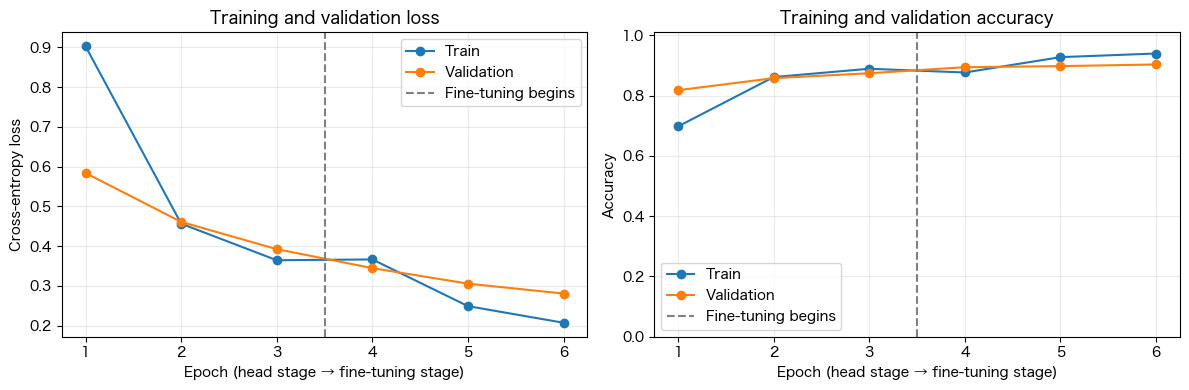

Best validation loss, head-only / 分類層のみ: 0.3926
Best validation loss, fine-tuning / 微調整: 0.2809
Training times / 学習時間: {'head_s': 31.9, 'fine_tune_s': 37.8}


In [14]:
combined = {key: history_head[key] + history_ft[key] for key in history_head}
xs = np.arange(1, len(combined['train_loss']) + 1)
change_point = len(history_head['train_loss']) + 0.5
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(xs, combined['train_loss'], '-o', label='Train')
axes[0].plot(xs, combined['val_loss'], '-o', label='Validation')
axes[0].set_ylabel('Cross-entropy loss')
axes[0].set_title('Training and validation loss')
axes[1].plot(xs, combined['train_acc'], '-o', label='Train')
axes[1].plot(xs, combined['val_acc'], '-o', label='Validation')
axes[1].set_ylim(0, 1.01)
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Training and validation accuracy')
for ax in axes:
    ax.axvline(change_point, color='gray', linestyle='--', label='Fine-tuning begins')
    ax.set_xlabel('Epoch (head stage → fine-tuning stage)')
    ax.set_xticks(xs)
    ax.grid(alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()

print('Best validation loss, head-only / 分類層のみ:', round(val_head, 4))
print('Best validation loss, fine-tuning / 微調整:', round(val_ft, 4))
print('Training times / 学習時間:', {'head_s': round(time_head, 1),
                                 'fine_tune_s': round(time_ft, 1)})

## 8. Evaluate on held-out test images / 独立したテスト画像で評価

**EN:** We have already selected the model using **validation loss**. Now, and only now, we evaluate **all held-out test photos**. The confusion matrix shows which classes are confused. The per-class report shows precision, recall, and F1-score. This is the appropriate stage to compare against the small CNN from Notebook 2 if its test data split is the same.

**日本語：** **検証損失**で最終モデルを選んだ後、初めて**すべてのテスト画像**で評価します。混同行列では間違えたクラスの組み合わせ、クラス別レポートでは適合率・再現率・F1を確認できます。2冊目の自作CNNと比較する場合は、同じテスト分割であることを確認してください。

Test accuracy / テスト正解率: 92.38% (551 images)
              precision    recall  f1-score   support

       daisy      0.918     0.947     0.933        95
   dandelion      0.942     0.956     0.949       135
       roses      0.888     0.906     0.897        96
  sunflowers      0.960     0.914     0.937       105
      tulips      0.907     0.892     0.899       120

    accuracy                          0.924       551
   macro avg      0.923     0.923     0.923       551
weighted avg      0.924     0.924     0.924       551



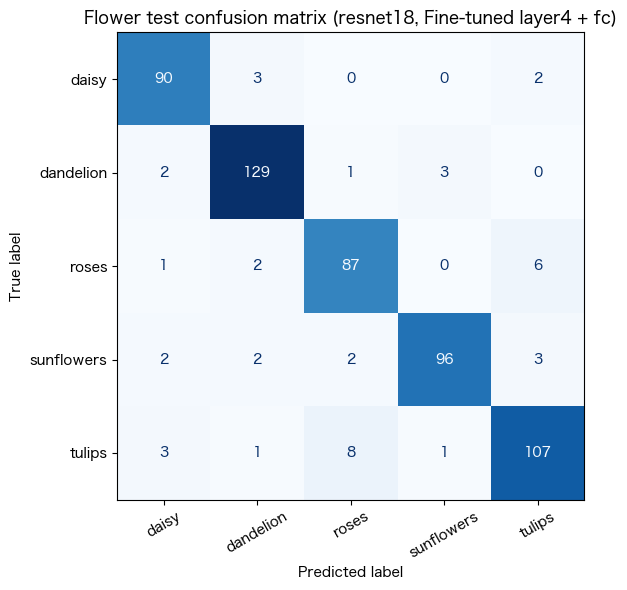

In [15]:
model.eval()
true_labels, pred_labels, confidence_scores = [], [], []
with torch.no_grad():
    for images, labels in test_loader:
        logits = model(images.to(DEVICE))
        probs = torch.softmax(logits, dim=1).cpu()
        true_labels.extend(labels.tolist())
        pred_labels.extend(probs.argmax(dim=1).tolist())
        confidence_scores.extend(probs.max(dim=1).values.tolist())

true_labels = np.asarray(true_labels)
pred_labels = np.asarray(pred_labels)
confidence_scores = np.asarray(confidence_scores)
test_acc = (true_labels == pred_labels).mean()
print(f'Test accuracy / テスト正解率: {test_acc:.2%} ({len(true_labels)} images)')
print(classification_report(true_labels, pred_labels,
                            labels=list(range(num_classes)),
                            target_names=class_names, digits=3, zero_division=0))
cm = confusion_matrix(true_labels, pred_labels, labels=list(range(num_classes)))
fig, ax = plt.subplots(figsize=(8.5, 6))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, cmap='Blues', colorbar=False, xticks_rotation=30)
ax.set_title(f'Flower test confusion matrix ({MODEL_NAME}, {best_phase})')
plt.tight_layout()
plt.show()

### Display mistakes and predicted scores / 誤分類と予測スコア

**EN:** Examine the actual photos behind mistakes. A high softmax score does **not** necessarily mean the prediction is truly well-calibrated; it is the model's relative score after softmax.

**日本語：** 間違った画像を見て、背景、色、花の形、見え方などを検討します。softmaxスコアが高くても、その予測確率が正しく校正されているとは限りません。

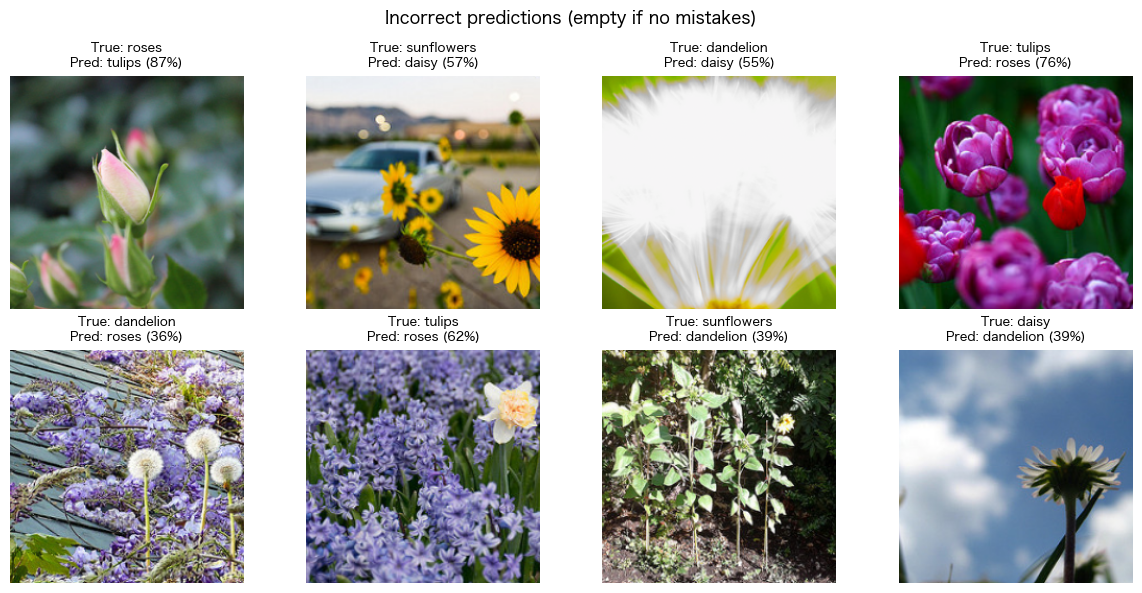

Number of incorrect test predictions / テストの誤分類枚数: 42


In [16]:
wrong = np.flatnonzero(true_labels != pred_labels)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, index in zip(axes.flat, wrong[:8]):
    image, _ = test_data[int(index)]
    ax.imshow(denormalize(image))
    ax.set_title(f'True: {class_names[true_labels[index]]}\n'
                 f'Pred: {class_names[pred_labels[index]]} '
                 f'({confidence_scores[index]:.0%})', fontsize=9)
    ax.axis('off')
for ax in list(axes.flat)[min(len(wrong), 8):]:
    ax.axis('off')
plt.suptitle('Incorrect predictions (empty if no mistakes)')
plt.tight_layout()
plt.show()
print('Number of incorrect test predictions / テストの誤分類枚数:', len(wrong))

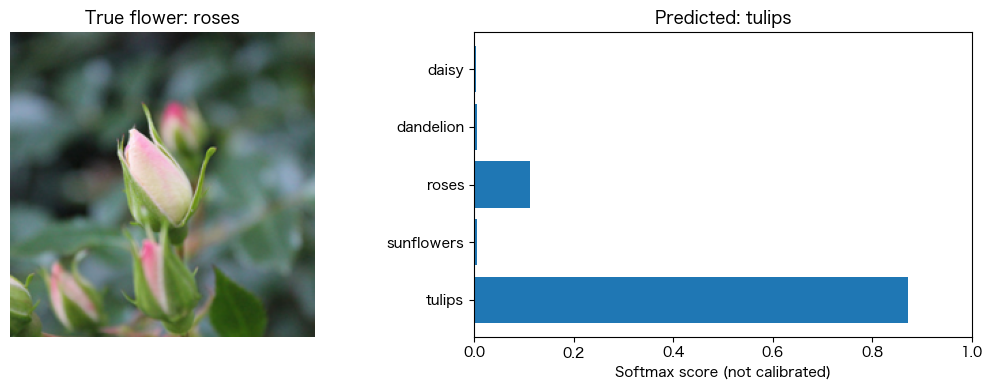

In [17]:
# Choose an error when possible; otherwise choose a correct prediction.
# 誤分類例があればそれを、なければ正しく分類できた画像を使用。
example_index = int(wrong[0]) if len(wrong) else 0
sample_img, sample_label = test_data[example_index]
model.eval()
with torch.no_grad():
    logits = model(sample_img.unsqueeze(0).to(DEVICE))
    p = torch.softmax(logits, dim=1)[0].cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].imshow(denormalize(sample_img))
axes[0].axis('off')
axes[0].set_title(f'True flower: {class_names[sample_label]}')
axes[1].barh(class_names, p)
axes[1].invert_yaxis()
axes[1].set_xlim(0, 1)
axes[1].set_xlabel('Softmax score (not calibrated)')
axes[1].set_title(f'Predicted: {class_names[int(p.argmax())]}')
plt.tight_layout()
plt.show()

## 9. Visualize intermediate features / 中間特徴マップを可視化

**EN:** A *forward hook* saves layer outputs without changing the trained model. Earlier ResNet layers retain fine spatial patterns, while deeper layers combine many signals. Each channel uses its own color scale; **do not compare colors numerically across separate panels**. Feature maps show activations, not a definitive explanation for a model's decision.

**日本語：** *forward hook* でモデルの重みを変えずに中間出力を保存します。前半には細かい位置情報が残り、後半ではさまざまな情報が組み合わさります。**各図の色スケールは別々**なので、色だけで数値の大小を比較しないでください。特徴マップは活性化を示しますが、判断理由の厳密な証明ではありません。

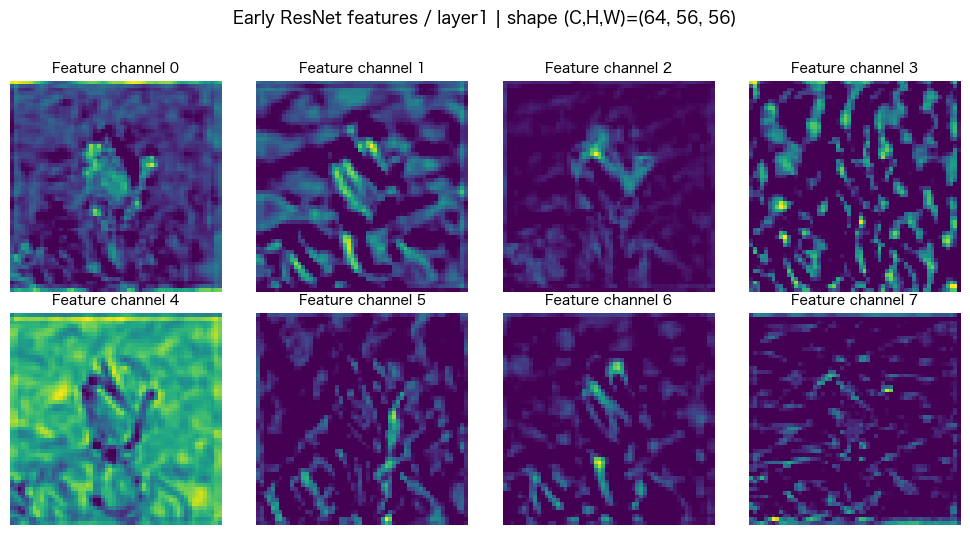

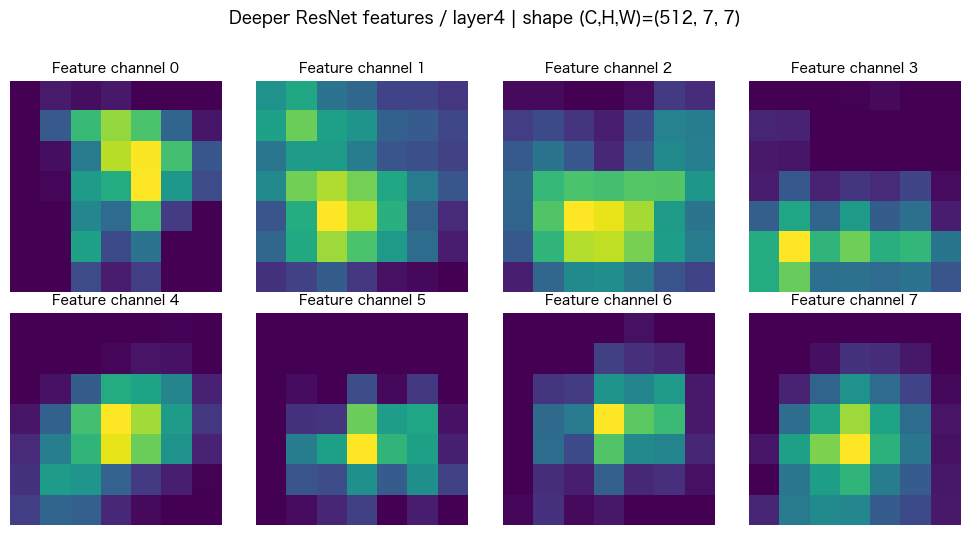

In [18]:
def capture_feature_maps(net, image, layer):
    store = {}
    def save_activation(module, inputs, output):
        store['activation'] = output.detach().cpu()
    hook = layer.register_forward_hook(save_activation)
    try:
        net.eval()
        with torch.no_grad():
            net(image.unsqueeze(0).to(DEVICE))
    finally:
        hook.remove()
    return store['activation'][0]

def show_maps(maps, title, n=8):
    cols = 4
    n = min(n, maps.shape[0])
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(10, 2.6 * rows))
    for j, ax in enumerate(np.array(axes).flat):
        if j < n:
            ax.imshow(maps[j].numpy(), cmap='viridis')
            ax.set_title(f'Feature channel {j}', fontsize=10)
        ax.axis('off')
    fig.suptitle(f'{title} | shape (C,H,W)={tuple(maps.shape)}', y=1.02)
    plt.tight_layout()
    plt.show()

features_early = capture_feature_maps(model, sample_img, model.layer1)
features_late = capture_feature_maps(model, sample_img, model.layer4)
show_maps(features_early, 'Early ResNet features / layer1', n=8)
show_maps(features_late, 'Deeper ResNet features / layer4', n=8)

## 10. Optional: Grad-CAM heatmap / 発展：Grad-CAMヒートマップ

**EN:** Grad-CAM combines gradients with deep feature maps to highlight image regions associated with a chosen class score. It is a **visual diagnostic**, not proof of causality or a guaranteed explanation. Bright colors indicate higher Grad-CAM activation. We calculate it using the final `layer4` feature tensor and upsample the result onto the input image.

**日本語：** Grad-CAMは勾配と深い特徴マップを組み合わせ、あるクラスのスコアに関係する画像領域を強調します。ただし、これは**可視化による診断**であり、因果関係や判断理由を保証するものではありません。明るい領域ほどGrad-CAMの値が高くなります。

**Note / 注意:** This runs one backward pass for visualization; it does not update model weights. / 可視化のために逆伝播を1回行いますが、重みは更新しません。

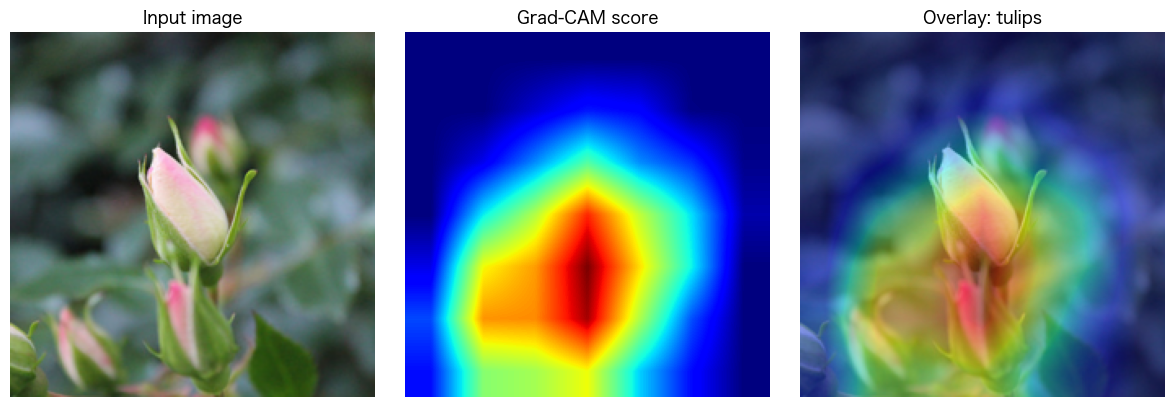

In [19]:
import torch.nn.functional as F

def grad_cam_for_image(net, image, target_class=None):
    """Compute Grad-CAM for ResNet layer4; returns a normalized 2D numpy map."""
    captured = {}
    def forward_hook(module, inputs, output):
        captured['features'] = output
        # Capture gradient w.r.t. the activation tensor, not the model weights.
        output.register_hook(lambda grad: captured.update(gradients=grad))

    handle = net.layer4.register_forward_hook(forward_hook)
    try:
        net.eval()
        net.zero_grad(set_to_none=True)
        with torch.enable_grad():
            logits = net(image.unsqueeze(0).to(DEVICE))
            predicted_class = int(logits.argmax(dim=1).item())
            target_class = predicted_class if target_class is None else int(target_class)
            logits[0, target_class].backward()
        feat = captured['features'].detach()[0]  # [C,H,W]
        grad = captured['gradients'].detach()[0]  # [C,H,W]
        importance = grad.mean(dim=(1,2), keepdim=True)
        cam = torch.relu((importance * feat).sum(dim=0, keepdim=True))
        cam = F.interpolate(cam.unsqueeze(0), size=image.shape[-2:],
                            mode='bilinear', align_corners=False)[0, 0]
        cam = cam - cam.min()
        cam = cam / cam.max().clamp_min(1e-8)
        return cam.cpu().numpy(), predicted_class, target_class
    finally:
        handle.remove()
        net.zero_grad(set_to_none=True)

cam, predicted_idx, target_idx = grad_cam_for_image(model, sample_img)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
rgb = denormalize(sample_img)
axes[0].imshow(rgb)
axes[0].set_title('Input image')
axes[1].imshow(cam, cmap='jet', vmin=0, vmax=1)
axes[1].set_title('Grad-CAM score')
axes[2].imshow(rgb)
axes[2].imshow(cam, cmap='jet', alpha=0.42, vmin=0, vmax=1)
axes[2].set_title(f'Overlay: {class_names[target_idx]}')
for ax in axes: ax.axis('off')
plt.tight_layout()
plt.show()

## 11. Save your model / モデルの保存

**EN:** Save `state_dict()` and simple metadata separately. Saving just weights is safer and easier to reload than pickling an entire Python model. To reload later, construct a model of the same architecture with `weights=None`, change its `fc` output count, and load the saved `state_dict`. Store the flower class order as well: the numeric outputs `0..4` are meaningful only when mapped to the correct names.

**日本語：** `state_dict()` とメタデータを別々に保存します。モデル全体をPythonオブジェクトとして保存するより、重みだけの保存の方が再利用しやすく安全です。読み込み時は同じResNet構造を用意し、`fc` を5クラスに変更して重みを読み込みます。クラス名の並び順も保存してください。

In [20]:
SAVE_DIR = Path('./trained_flower_models')
SAVE_DIR.mkdir(parents=True, exist_ok=True)
weights_path = SAVE_DIR / f'{MODEL_NAME}_flowers_finetuned_state_dict.pth'
metadata_path = SAVE_DIR / f'{MODEL_NAME}_flowers_metadata.json'

torch.save(model.state_dict(), weights_path)
metadata = {
    'model_name': MODEL_NAME,
    'class_names': class_names,
    'selected_phase': best_phase,
    'input_crop_size': 224,
    'normalization_mean': list(mean),
    'normalization_std': list(std),
    'seed': SEED,
    'quick_demo': QUICK_DEMO,
    'test_accuracy': float(test_acc)
}
metadata_path.write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding='utf-8')
print('Saved model weights / モデル重み:', weights_path.resolve())
print('Saved metadata / メタデータ:', metadata_path.resolve())

# Optional reload test / 任意：保存データの再読み込みを検証
reloaded = (models.resnet18(weights=None) if MODEL_NAME == 'resnet18'
            else models.resnet50(weights=None))
reloaded.fc = nn.Linear(reloaded.fc.in_features, num_classes)
reloaded.load_state_dict(torch.load(weights_path, map_location='cpu', weights_only=True))
reloaded.eval()
print('Reload successful / 再読み込みに成功')
del reloaded

Saved model weights / モデル重み: /Users/matustanonwong/Desktop/Assistant Professor /Fall Semester 2026/研修１/codes/Week-2/trained_flower_models/resnet18_flowers_finetuned_state_dict.pth
Saved metadata / メタデータ: /Users/matustanonwong/Desktop/Assistant Professor /Fall Semester 2026/研修１/codes/Week-2/trained_flower_models/resnet18_flowers_metadata.json
Reload successful / 再読み込みに成功


## 12. Discussion, comparison, and small exercises / 考察・比較・小課題

| Question (EN) | 質問（日本語） |
|---|---|
| What does *pretrained* mean? | 「学習済み」とはどういう意味ですか？ |
| Why do we replace the last layer with five outputs? | なぜ最後の層を5出力へ変更しますか？ |
| What is frozen during feature extraction? | 特徴抽出の段階では何を固定しますか？ |
| Which part changes during fine-tuning? | ファインチューニングでどの層を更新しますか？ |
| Why should the LR for pretrained layers be small? | 学習済みの層に小さな学習率を使うのはなぜですか？ |
| Does ResNet50 always beat ResNet18? | ResNet50はResNet18より必ず良いですか？ |
| What changed compared with our from-scratch flower CNN? | 自作CNNと何が違いますか？ |

### Experiments / 実験

**Experiment A:** Change `MODEL_NAME='resnet50'` in Section 0 and rerun from the beginning. Track training time, validation loss, test accuracy, and model size. / `MODEL_NAME='resnet50'` に変えて最初から実行し、時間・検証損失・テスト精度・モデルサイズを比較してください。

**Experiment B:** Compare **head-only** vs **fine-tuned** validation losses in Section 7. Did fine-tuning help? / 分類層のみと微調整ありの**検証損失**を比較し、改善したか考察してください。

**Experiment C:** If you ran Notebook 2 with the same full test split, compare test accuracy, per-class recall, and computation. A pre-trained model uses more computation but may generalize better with limited training data. / 2冊目と同じテスト分割なら精度・クラス別再現率・計算時間を比較しましょう。学習済みモデルは計算量が増えても、少量の学習データで有利な場合があります。

### References / 参考資料
- PyTorch transfer learning tutorial: https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html
- Torchvision ResNet18 documentation: https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html
- Torchvision ResNet50 documentation: https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet50.html
- ResNet paper, He et al. (2016): https://arxiv.org/abs/1512.03385
- Flower sample dataset: https://www.tensorflow.org/tutorials/images/classification?hl=ja

**Teacher note / 教員向け：** For a time-limited class, run Sections 0–8 before class once; leave Grad-CAM and ResNet50 as optional advanced activities. / 授業前に0〜8を一度動かしておき、Grad-CAMとResNet50は発展課題にすると無理がありません。